In [1]:
import pickle
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, f1_score, confusion_matrix, balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
with open('/home/matildxi/Secretária/Documentos/Tese/DANN/wesad/processed_data_sequences.pkl', 'rb') as f:
    data = pickle.load(f)

X_seq      = data['X_seq']
y_seq      = data['y_seq']
groups_seq = data['groups_seq']

le = LabelEncoder()
domain_labels = le.fit_transform(groups_seq)

In [3]:
print(X_seq.shape)
print(y_seq.shape)
print(np.unique(y_seq))

(27543, 16, 60)
(27543,)
[0 1]


In [4]:
selected_idx = [0, 5, 6, 7, 8] 

X_seq = X_seq[:, selected_idx, :] 

In [5]:
class RNN1D(nn.Module):
    def __init__(self, input_size=5, hidden_size=128, num_layers=2, num_classes=2):
        super().__init__()
        self.rnn = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.3,
            bidirectional=True
        )
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 128),  # *2 por ser bidirecional
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # x tem shape (batch, 16, 60) → RNN espera (batch, seq_len, features)
        x = x.permute(0, 2, 1)          # (batch, 60, 16)
        out, _ = self.rnn(x)
        out = out[:, -1, :]             # último timestep
        return self.classifier(out)

In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
logo   = LeaveOneGroupOut()

all_preds  = []
all_labels = []
fold_f1s   = []

subjects = np.unique(groups_seq)
print(f"Total subjects: {len(subjects)}\n")

for fold, (train_idx, test_idx) in enumerate(logo.split(X_seq, y_seq, groups=groups_seq)):
    subject_id = groups_seq[test_idx[0]]
    print(f"Fold {fold+1:2d} | Test subject: {subject_id}")

    X_train_raw = X_seq[train_idx]   # (n, 16, 60)
    y_train_raw = y_seq[train_idx]
    X_test_raw  = X_seq[test_idx]
    y_test_raw  = y_seq[test_idx]

    # SMOTE precisa de input 2D → flatten, resample, reshape de volta
    n_train, C, T = X_train_raw.shape
    X_flat = X_train_raw.reshape(n_train, C * T)

    smote = SMOTE(random_state=42)
    X_res, y_res = smote.fit_resample(X_flat, y_train_raw)
    X_res = X_res.reshape(-1, C, T)

    # Tensores
    X_tr = torch.tensor(X_res,       dtype=torch.float32)
    y_tr = torch.tensor(y_res,       dtype=torch.long)
    X_te = torch.tensor(X_test_raw,  dtype=torch.float32)
    y_te = torch.tensor(y_test_raw,  dtype=torch.long)

    train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)
    test_loader  = DataLoader(TensorDataset(X_te, y_te), batch_size=64)

    # Modelo e otimizador frescos por fold
    model     = RNN1D().to(device)
    criterion = nn.CrossEntropyLoss()          # SMOTE já balanceou, sem pesos
    optimizer = optim.Adam(model.parameters(), lr=5e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

    # Treino
    EPOCHS = 50
    best_f1 = 0
    patience = 10
    no_improve = 0
    
    for epoch in range(EPOCHS):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()
        scheduler.step()
    
        # validação rápida no próprio test fold (só para early stopping)
        model.eval()
        ep_preds = []
        with torch.no_grad():
            for xb, _ in test_loader:
                ep_preds.extend(model(xb.to(device)).argmax(1).cpu().numpy())
        ep_f1 = f1_score(y_te.numpy(), ep_preds, average='macro')
    
        if ep_f1 > best_f1:
            best_f1 = ep_f1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"           Early stop no epoch {epoch+1}")
                break
    
    model.load_state_dict(best_state)

    # Avaliação
    model.eval()
    fold_preds = []
    with torch.no_grad():
        for xb, _ in test_loader:
            fold_preds.extend(model(xb.to(device)).argmax(1).cpu().numpy())

    f1 = f1_score(y_te.numpy(), fold_preds, average='macro')
    fold_f1s.append(f1)
    all_preds.extend(fold_preds)
    all_labels.extend(y_te.numpy())
    print(f"           Macro F1: {f1:.4f}\n")
print(f"Média: {np.mean(fold_f1s):.4f}  |  Std: {np.std(fold_f1s):.4f}")
print()
print(classification_report(all_labels, all_preds, target_names=['no-stress', 'stress']))

Total subjects: 15

Fold  1 | Test subject: S10
           Early stop no epoch 14
           Macro F1: 0.5305

Fold  2 | Test subject: S11
           Early stop no epoch 12
           Macro F1: 0.8592

Fold  3 | Test subject: S13
           Early stop no epoch 26
           Macro F1: 0.9212

Fold  4 | Test subject: S14
           Early stop no epoch 23
           Macro F1: 0.7182

Fold  5 | Test subject: S15
           Early stop no epoch 13
           Macro F1: 0.8209

Fold  6 | Test subject: S16
           Early stop no epoch 15
           Macro F1: 0.9673

Fold  7 | Test subject: S17
           Early stop no epoch 11
           Macro F1: 0.8850

Fold  8 | Test subject: S2
           Early stop no epoch 11
           Macro F1: 0.9174

Fold  9 | Test subject: S3
           Early stop no epoch 33
           Macro F1: 0.8644

Fold 10 | Test subject: S4
           Early stop no epoch 15
           Macro F1: 0.9312

Fold 11 | Test subject: S5
           Early stop no epoch 14
           M

Estatísticas FINAIS - RNN + SMOTE
              precision    recall  f1-score   support

    baseline       0.88      0.89      0.89     17577
      stress       0.81      0.79      0.80      9966

    accuracy                           0.86     27543
   macro avg       0.84      0.84      0.84     27543
weighted avg       0.85      0.86      0.85     27543

Balanced Accuracy:        0.840
Macro F1 médio por fold:  0.835
Desvio Padrão F1 (LOSO):  0.104
Matthews Corr. Coef.:     0.685
Cohen's Kappa:            0.684

F1 por fold:
  Sujeito 01: 0.530
  Sujeito 02: 0.859
  Sujeito 03: 0.921
  Sujeito 04: 0.718
  Sujeito 05: 0.821
  Sujeito 06: 0.967
  Sujeito 07: 0.885
  Sujeito 08: 0.917
  Sujeito 09: 0.864
  Sujeito 10: 0.931
  Sujeito 11: 0.838
  Sujeito 12: 0.808
  Sujeito 13: 0.890
  Sujeito 14: 0.816
  Sujeito 15: 0.762


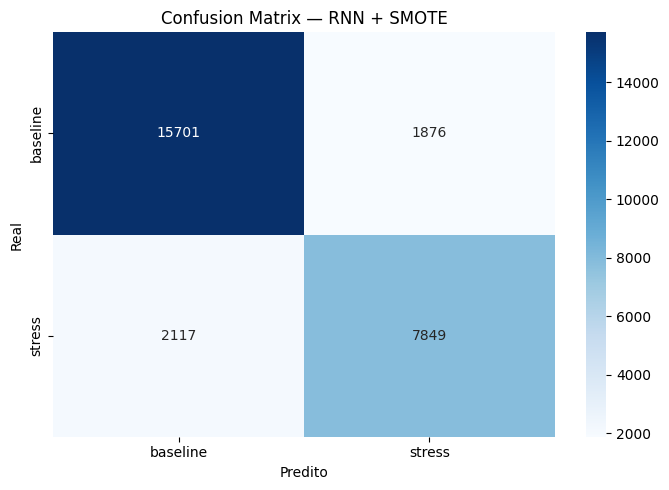

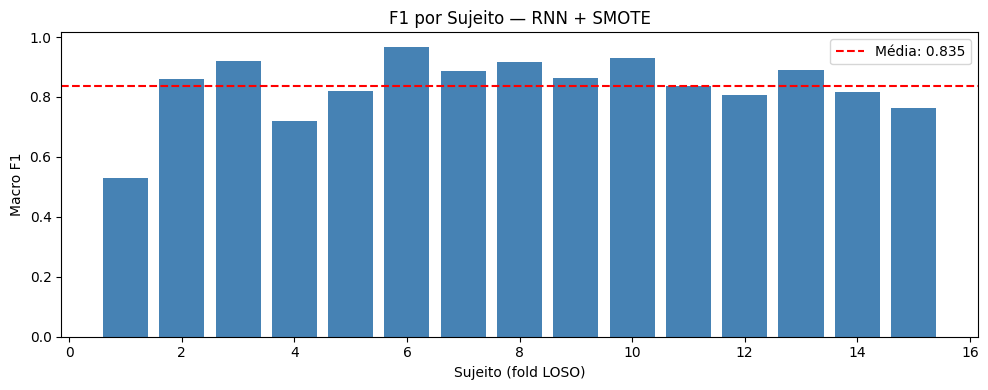

In [7]:
all_labels = np.array(all_labels)
all_preds  = np.array(all_preds)

print("=" * 50)
print("Estatísticas FINAIS - RNN + SMOTE")
print("=" * 50)
print(classification_report(all_labels, all_preds,
                             target_names=['baseline', 'stress'],
                             zero_division=0))
print(f"Balanced Accuracy:        {balanced_accuracy_score(all_labels, all_preds):.3f}")
print(f"Macro F1 médio por fold:  {np.mean(fold_f1s):.3f}")
print(f"Desvio Padrão F1 (LOSO):  {np.std(fold_f1s):.3f}")
print(f"Matthews Corr. Coef.:     {matthews_corrcoef(all_labels, all_preds):.3f}")
print(f"Cohen's Kappa:            {cohen_kappa_score(all_labels, all_preds):.3f}")

print(f"\nF1 por fold:")
subjects = np.unique(groups_seq)
for i, f1 in enumerate(fold_f1s):
    print(f"  Sujeito {i+1:02d}: {f1:.3f}")

# confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(all_labels, all_preds),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['baseline', 'stress'],
            yticklabels=['baseline', 'stress'])
plt.title('Confusion Matrix — RNN + SMOTE')
plt.ylabel('Real'); plt.xlabel('Predito')
plt.tight_layout()
plt.show()

# F1 por sujeito
plt.figure(figsize=(10, 4))
plt.bar(range(1, len(fold_f1s)+1), fold_f1s, color='steelblue')
plt.axhline(np.mean(fold_f1s), color='red', linestyle='--',
            label=f'Média: {np.mean(fold_f1s):.3f}')
plt.xlabel('Sujeito (fold LOSO)')
plt.ylabel('Macro F1')
plt.title('F1 por Sujeito — RNN + SMOTE')
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
n_total, C, T = X_seq.shape

X_flat = X_seq.reshape(n_total, C * T)
X_res, y_res = SMOTE(random_state=42).fit_resample(X_flat, y_seq)
X_res = X_res.reshape(-1, C, T)

X_tr = torch.tensor(X_res, dtype=torch.float32)
y_tr = torch.tensor(y_res, dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)

model_final = RNN1D().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_final.parameters(), lr=5e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

EPOCHS = 50
for epoch in range(EPOCHS):
    model_final.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        criterion(model_final(xb), yb).backward()
        optimizer.step()
    scheduler.step()

print("Treino concluído!")

# guardar
torch.save({
    'model_state_dict': model_final.state_dict(),
    'selected_idx': selected_idx,
}, '/home/matildxi/Secretária/Documentos/Tese/anxolotl/models_data/rnn_wrist_final.pt')

print("Guardado!")

Treino concluído!
Guardado!


In [ ]:
# ROC-AUC
from sklearn.metrics import roc_auc_score
import numpy as np
_auc = roc_auc_score(np.array(y_test), np.array(y_score))
print(f'ROC-AUC: {_auc:.3f}')

In [ ]:
# F1 @ Youden-optimal threshold
from sklearn.metrics import roc_curve, f1_score
import numpy as np
_yt = np.array(y_test); _ys = np.array(y_score)
_fpr, _tpr, _thr = roc_curve(_yt, _ys)
_t_opt = float(_thr[np.argmax(_tpr - _fpr)])
_f1opt = f1_score(_yt, (_ys >= _t_opt).astype(int), average='macro', zero_division=0)
print(f'F1@opt : {_f1opt:.3f}  (threshold={_t_opt:.3f})')